In [1]:
from skimage import io
import numpy as np
from matplotlib import pyplot as plt
import os
import gc

In [2]:
from tifffile import imsave
import os

# name_file = '3D_result/'+ amostra + '_segmented.tif'
directory_path= '3D_result/'
# List all files and directories
files = [file for file in os.listdir(directory_path) if file.endswith('tif')]

# Print the files
for file in files:
    print(file)

03_09_segmented.tif
04_09_segmented.tif
06_06_segmented.tif
07_06_segmented.tif
07_09_segmented.tif
09_06_segmented.tif
11_06_segmented.tif
22_08_segmented.tif
23_08_segmented.tif
28_08_segmented.tif
29_08_segmented.tif


In [3]:
def readAmostra(amostra):
    path_steel_stl= '../../steel/stl/'
    folder = os.path.join(path_steel_stl, amostra)
    file_combined = os.path.join(folder,'output_combined_matriz_fibras.tif')
    file_fibras = os.path.join(folder,'output_fibras.tif')
    image = io.imread(file_combined)
    mask = io.imread(file_fibras)
    return image, mask

def printSlicesResult(save_plotname, slice,image, mask, prediction):
    plt.figure(figsize=(24, 16))
    plt.subplot(131)
    plt.title('Imagem de Teste')
    plt.imshow(image[slice,:,:])
    plt.subplot(132)
    plt.title('Máscara')
    plt.imshow(mask[slice,:,:])
    plt.subplot(133)
    plt.title('Predição')
    plt.imshow(prediction[slice,:,:])
    plt.savefig(f'{save_plotname}.png',bbox_inches='tight') 
    plt.show()

def printSlicePrediction(save_plotname, slice, prediction):
    plt.figure(figsize=(24, 16))
    plt.imshow(prediction[slice,:,:])
    plt.savefig(f'{save_plotname}.png',bbox_inches='tight') 
    plt.show()

def readPredicao(file):
    directory_path = '3D_result/uint8/'
    fileimage = os.path.join(directory_path,file)
    prediction = io.imread(fileimage)
    return prediction

amostra 03_09 em processamento


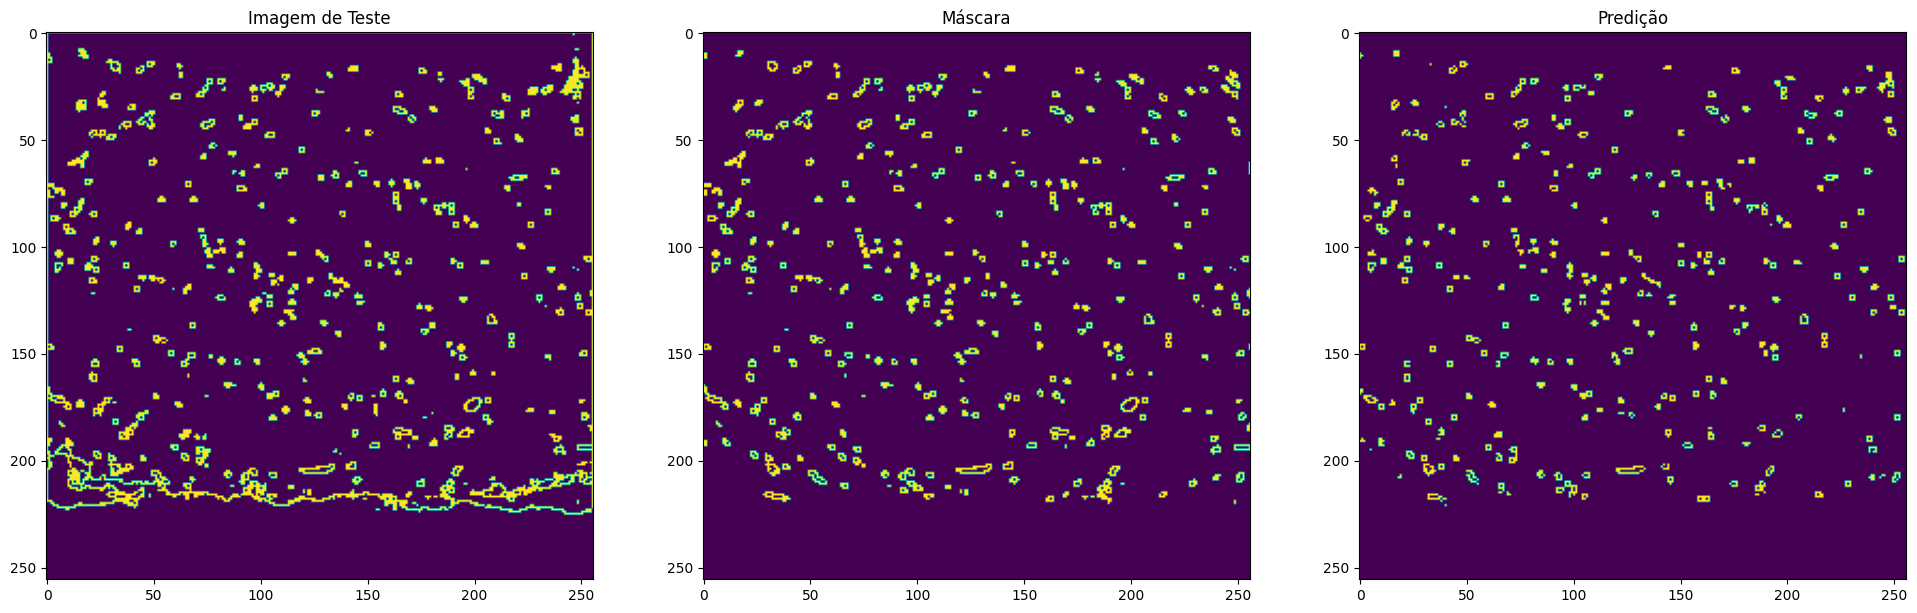

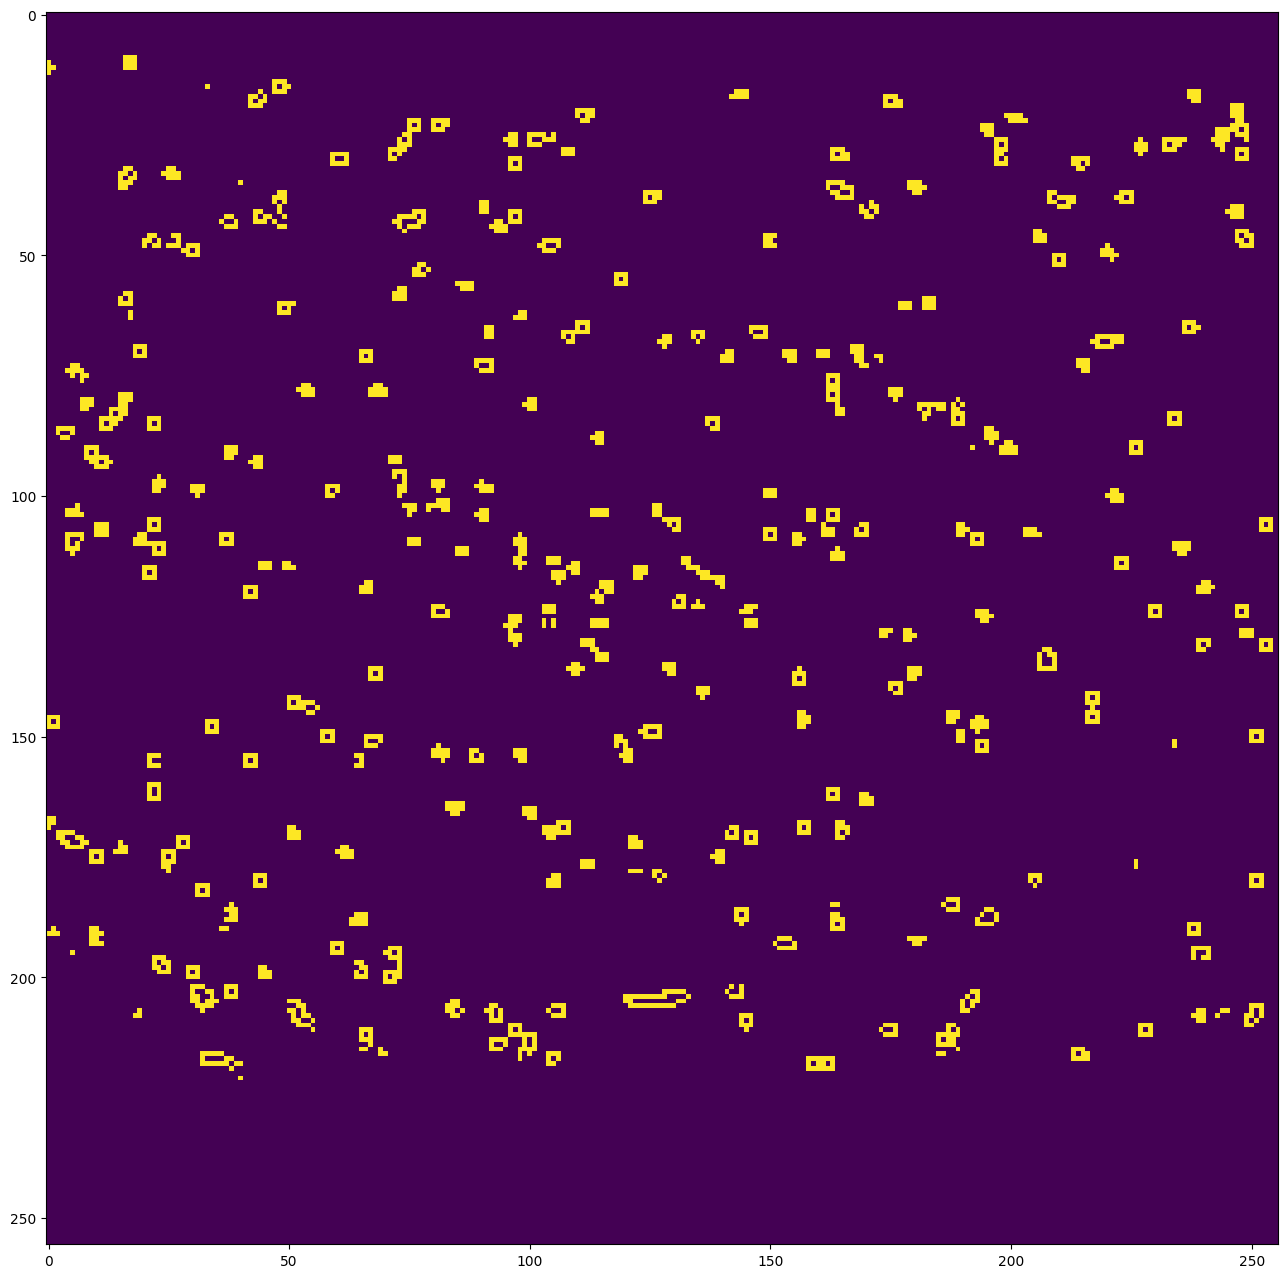

amostra 04_09 em processamento


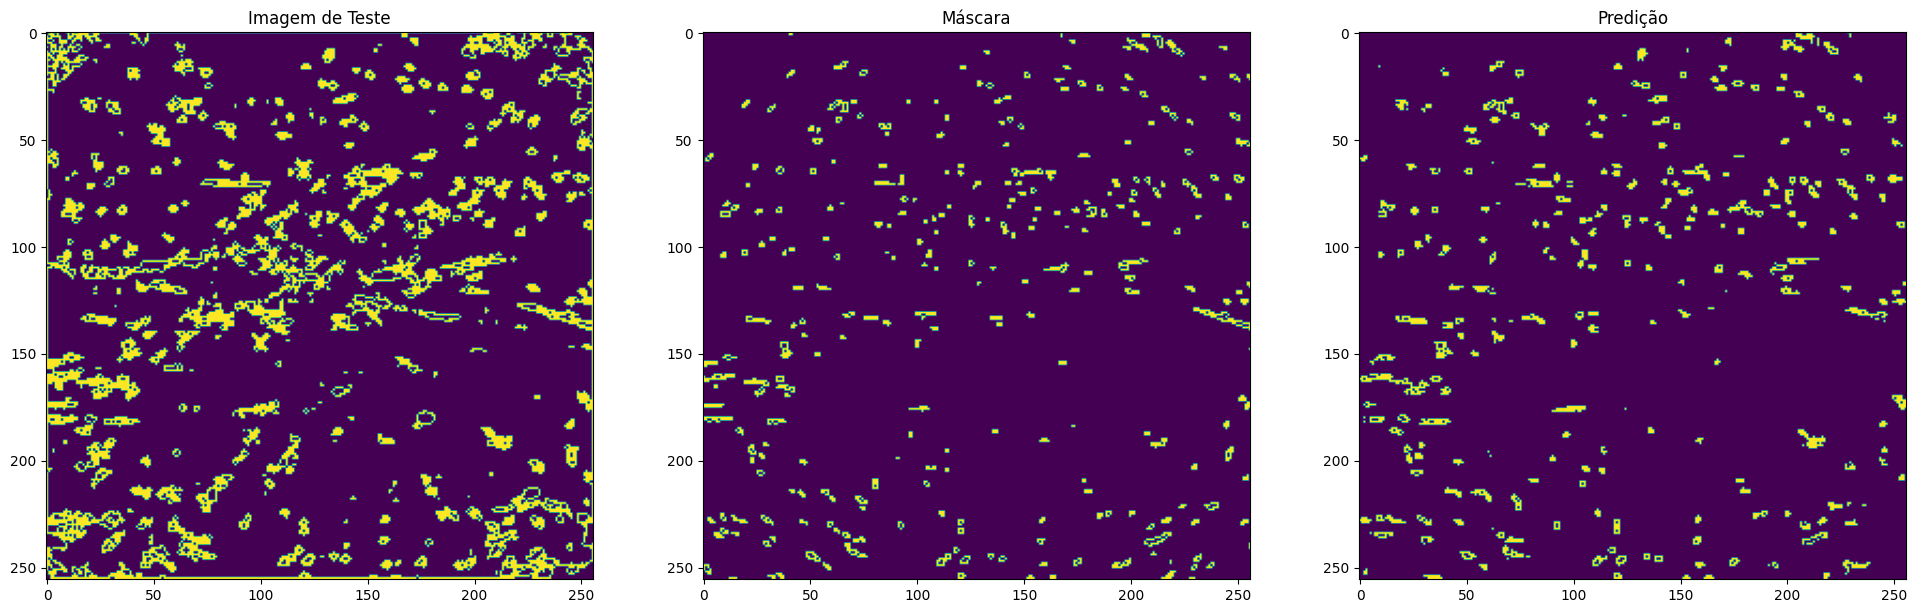

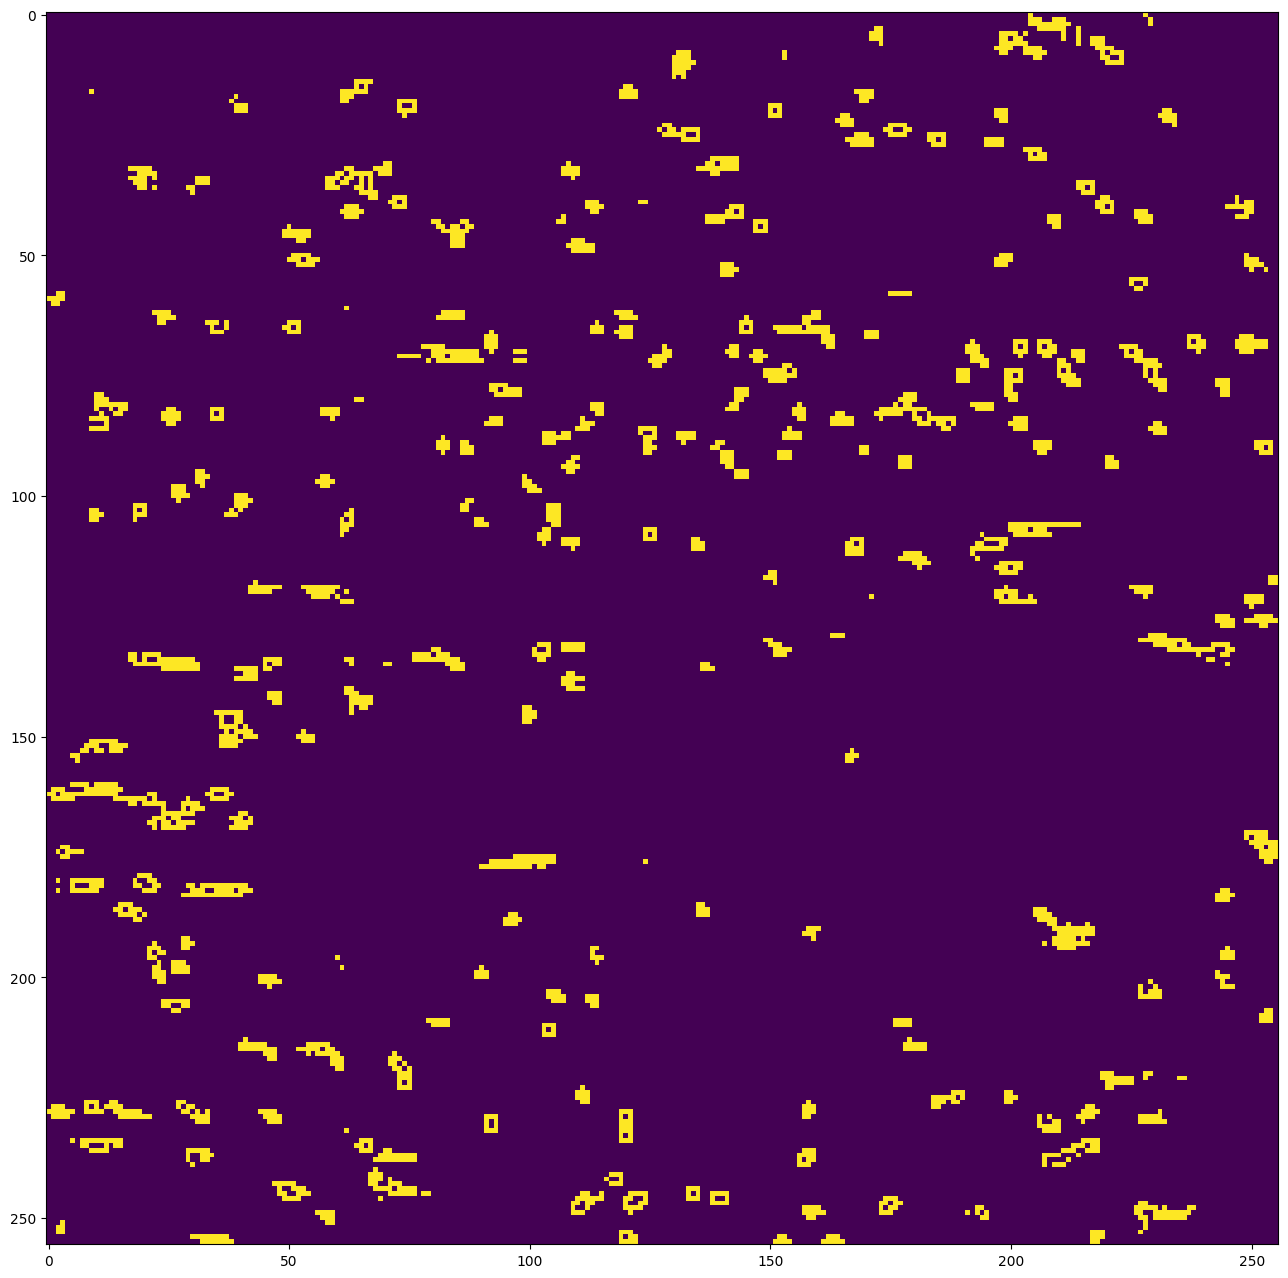

amostra 06_06 em processamento


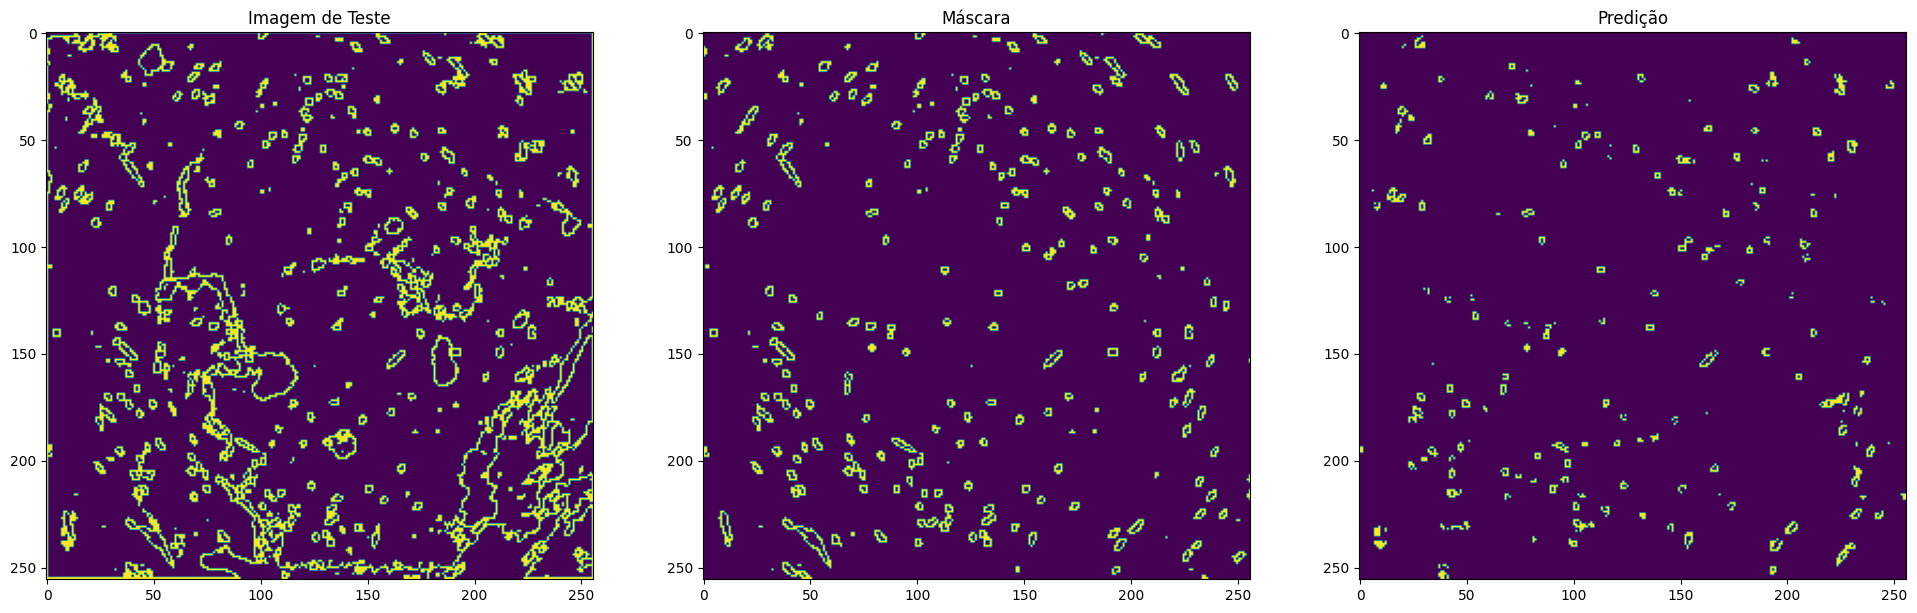

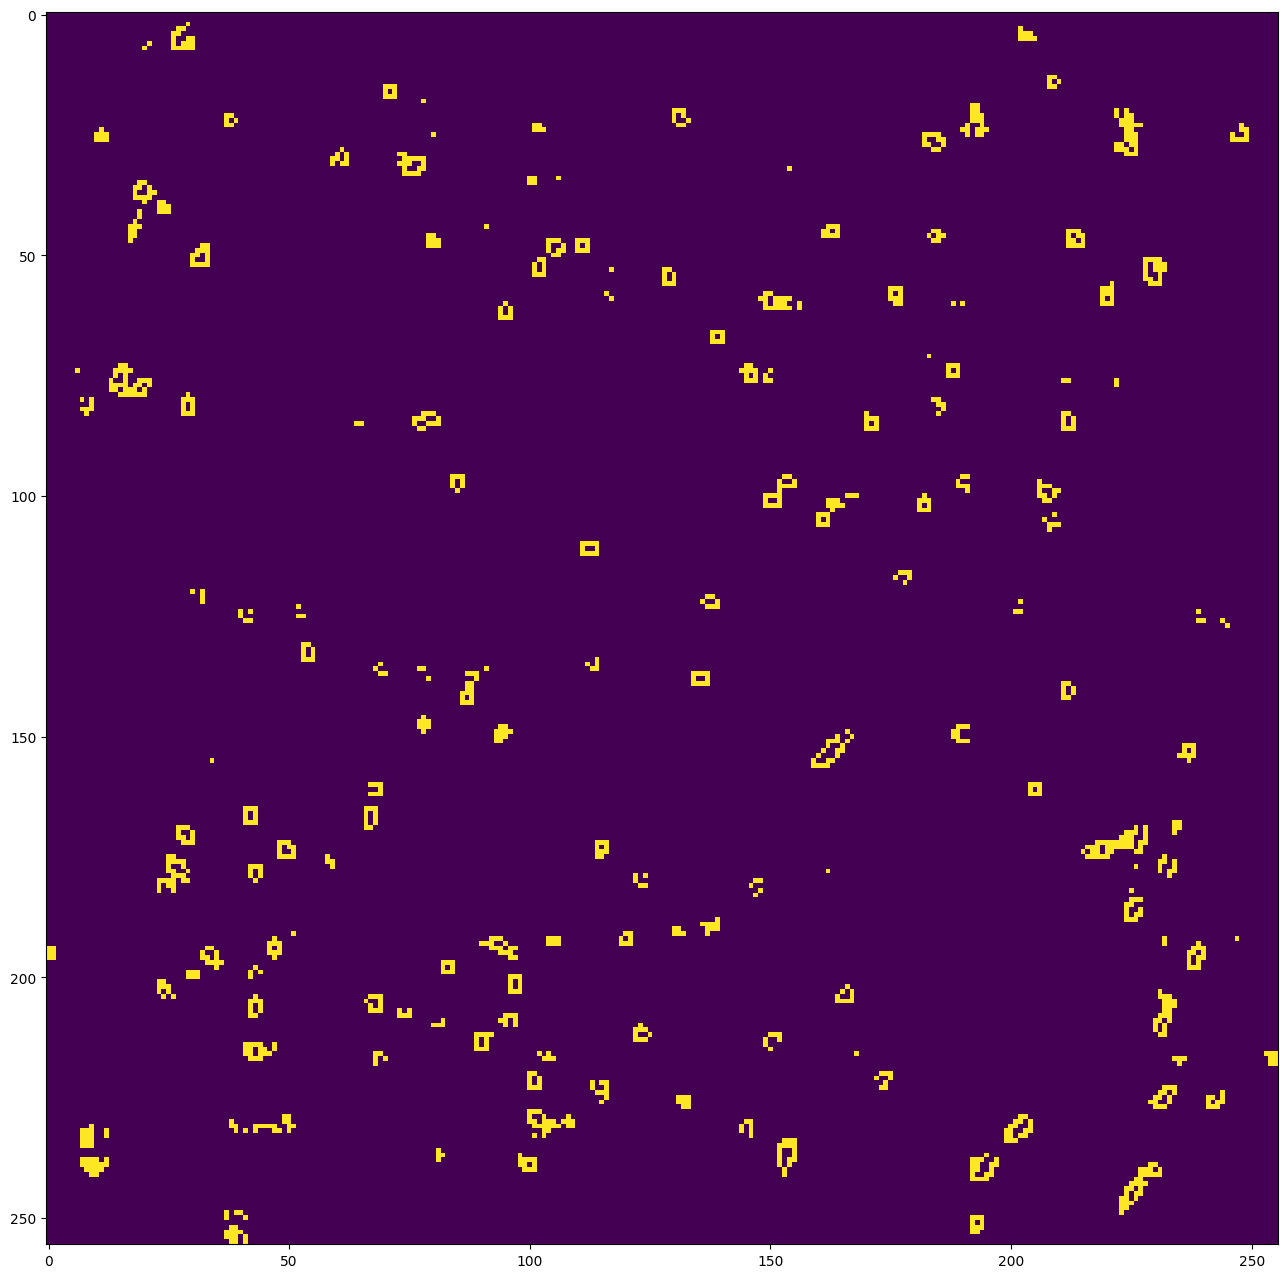

amostra 07_06 em processamento


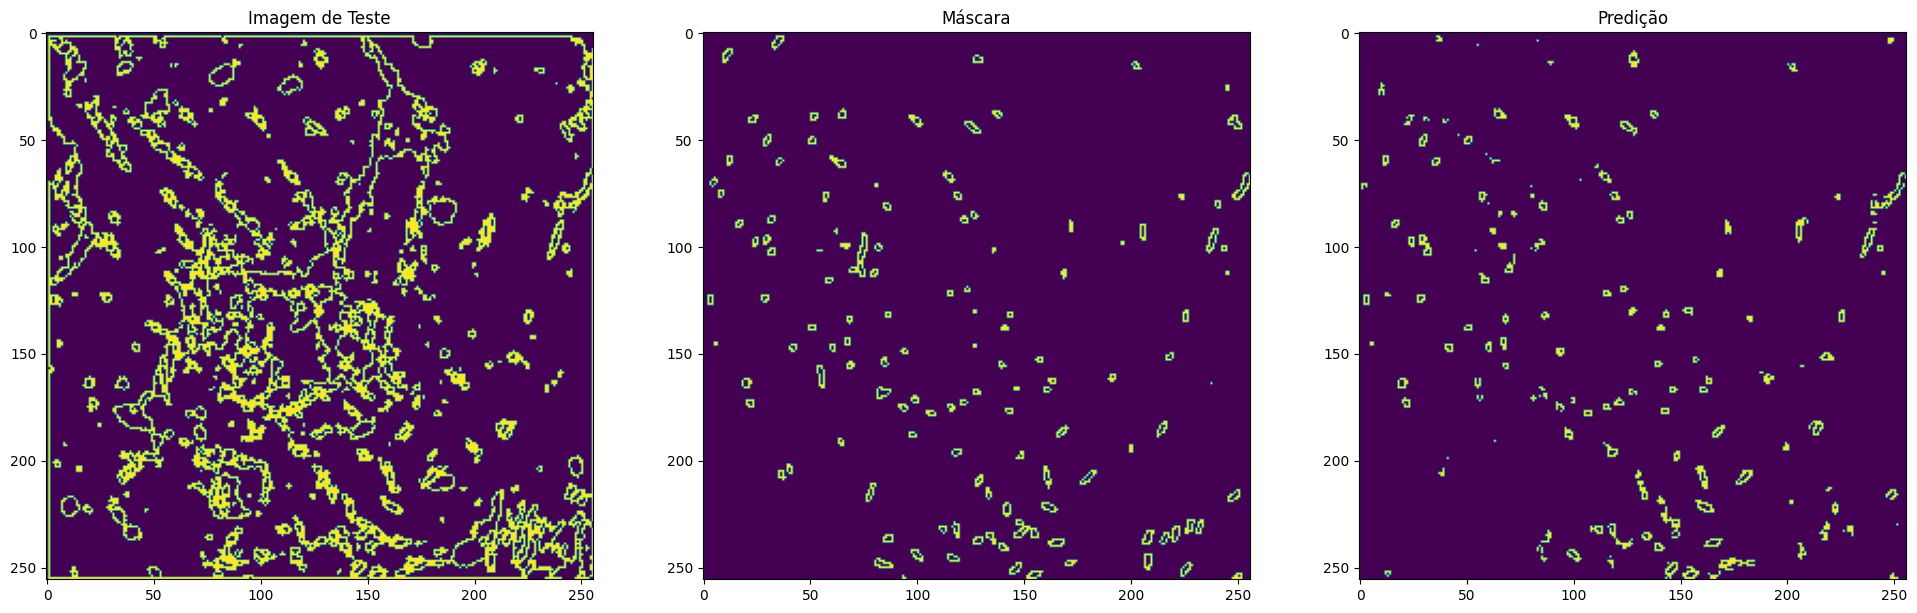

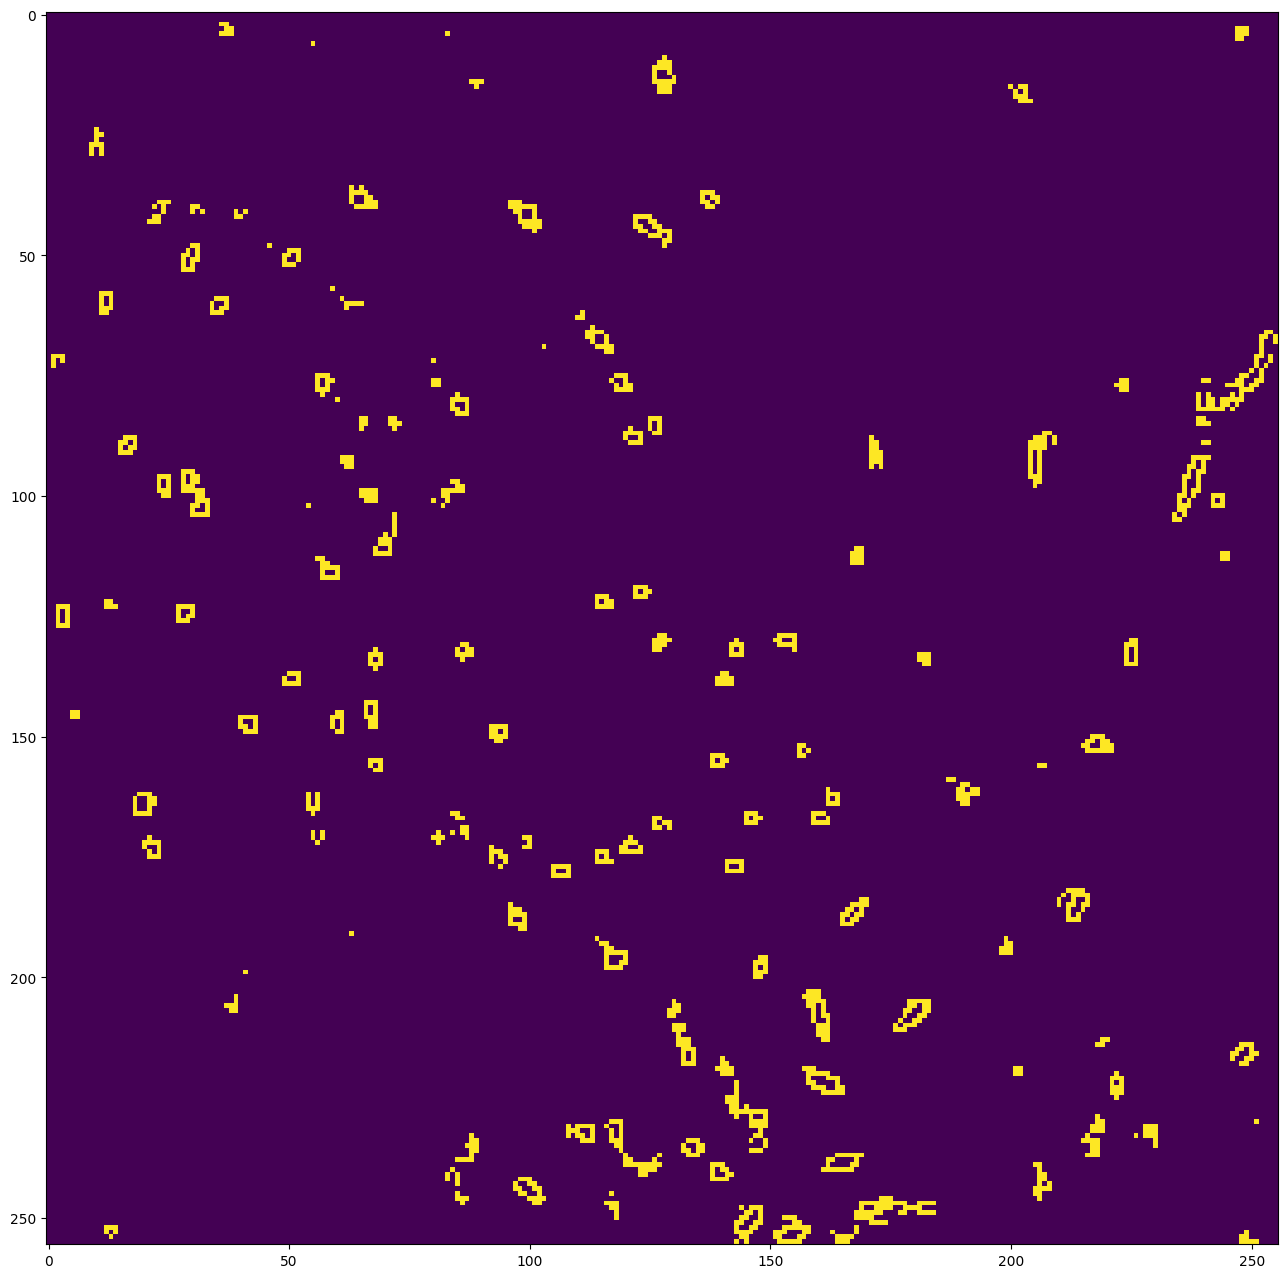

amostra 07_09 em processamento


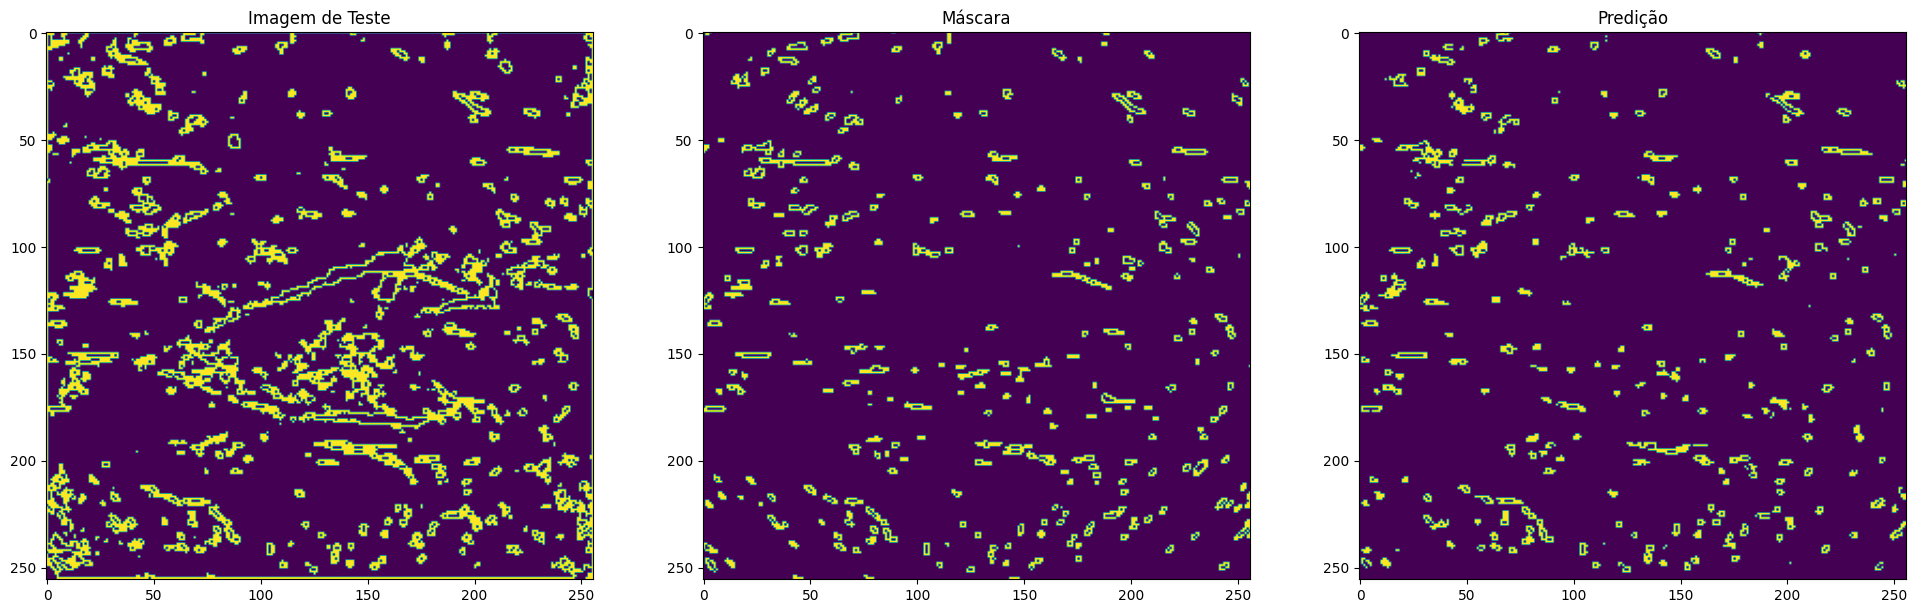

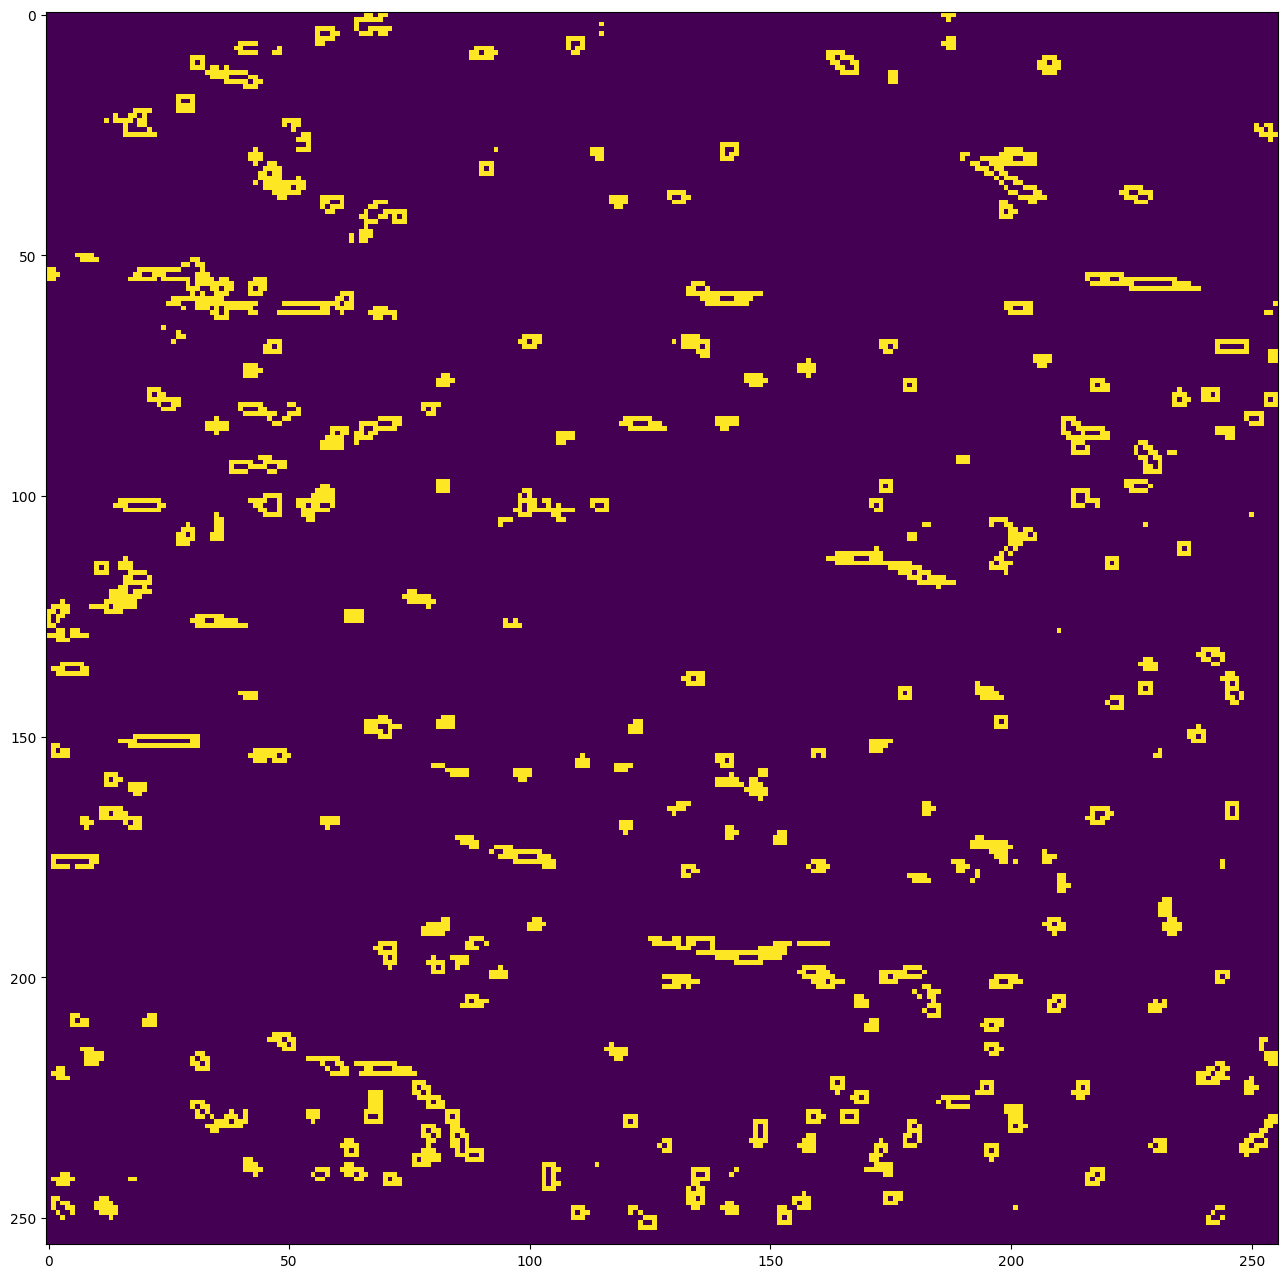

amostra 09_06 em processamento


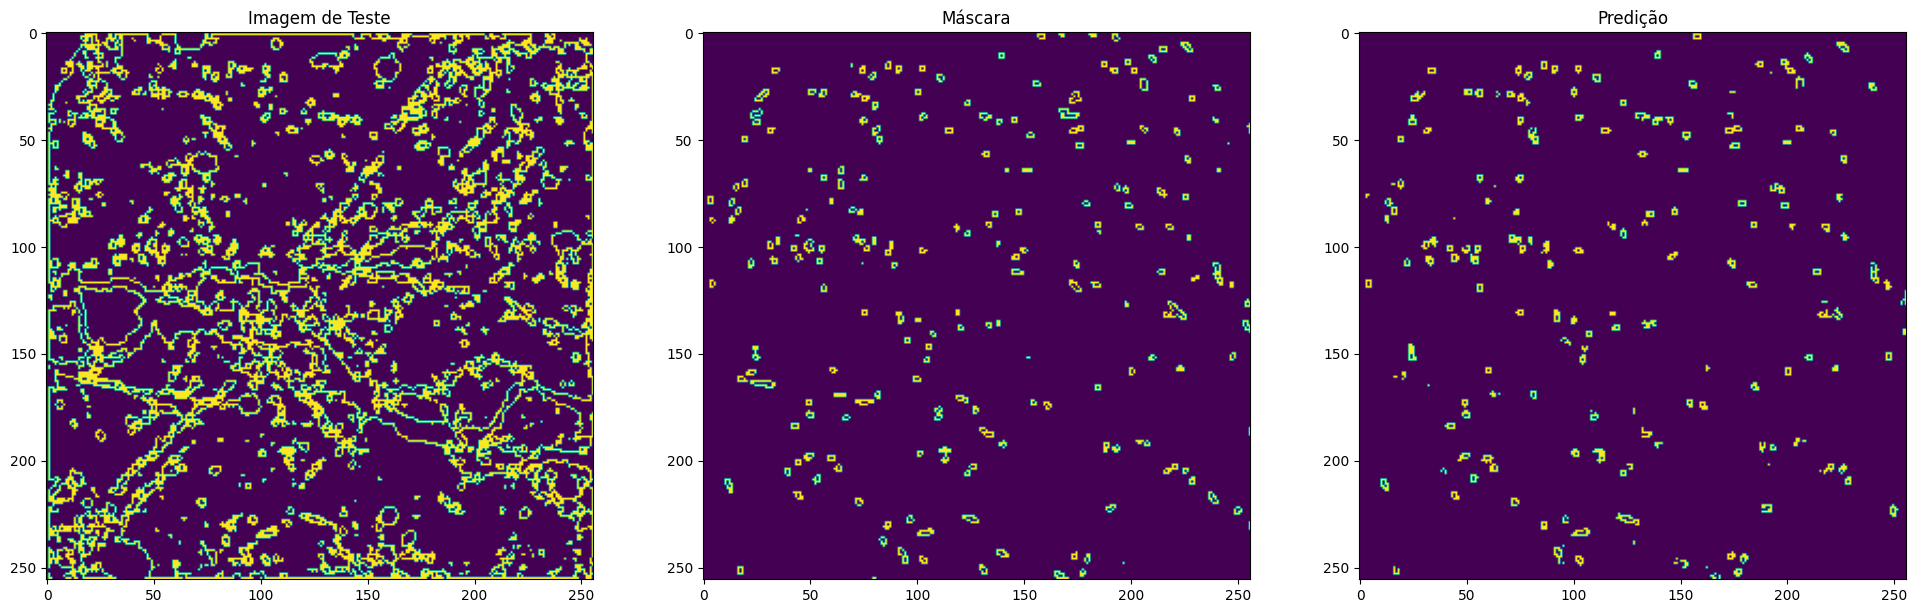

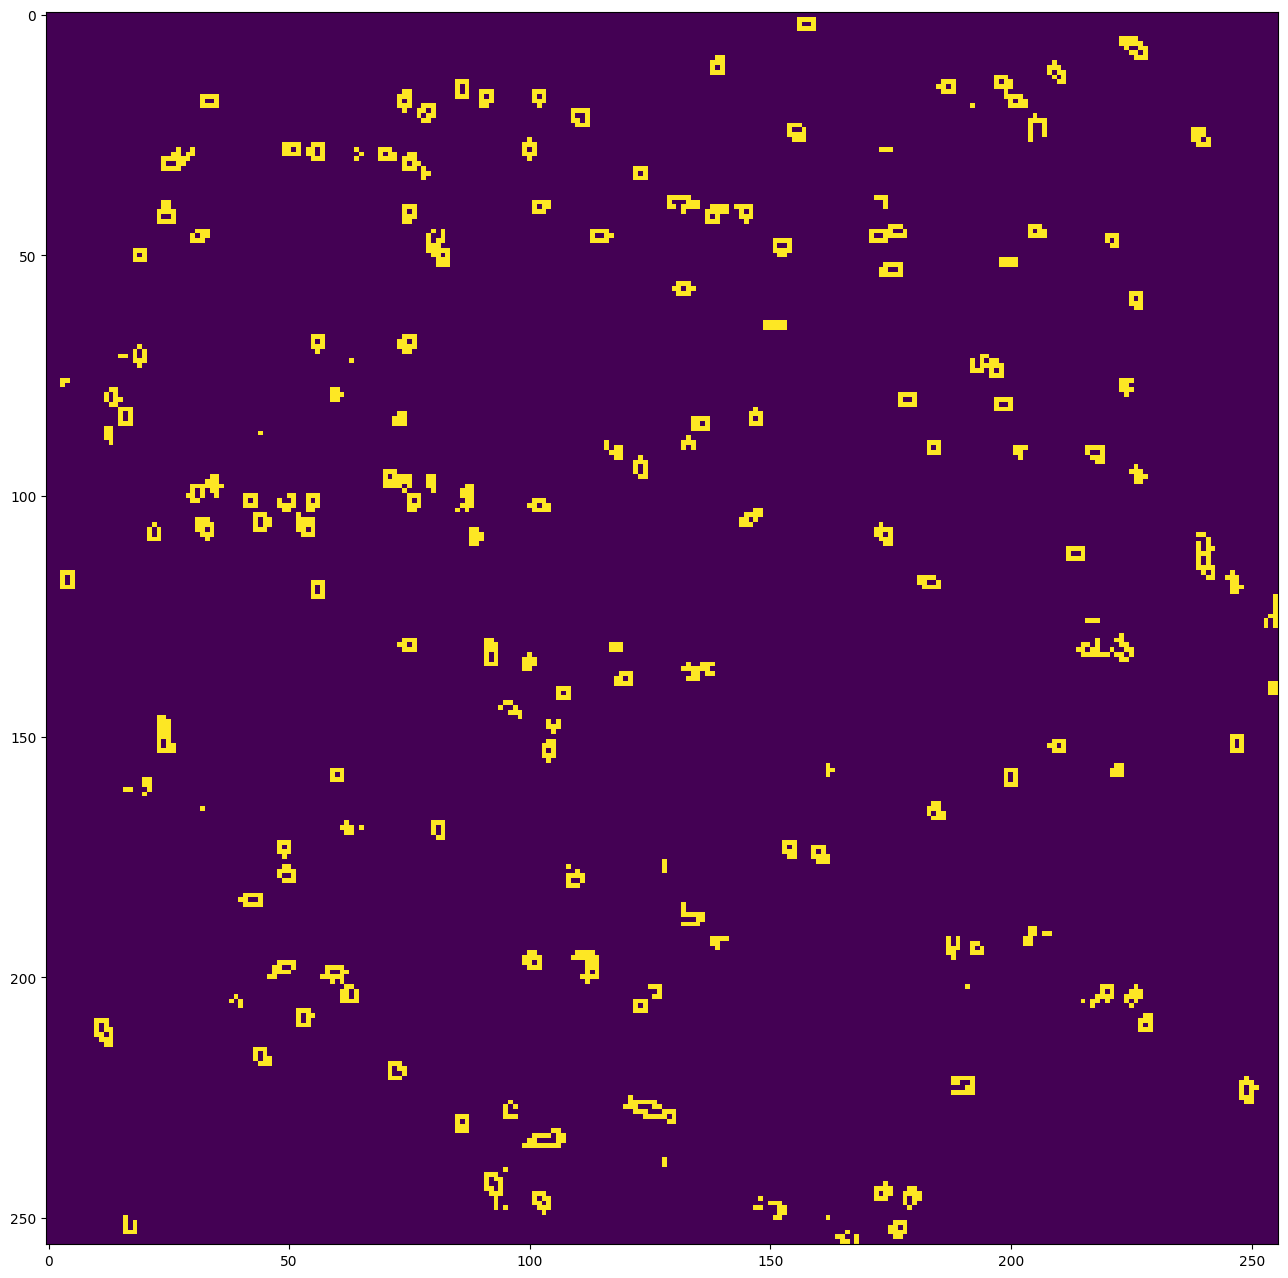

amostra 11_06 em processamento


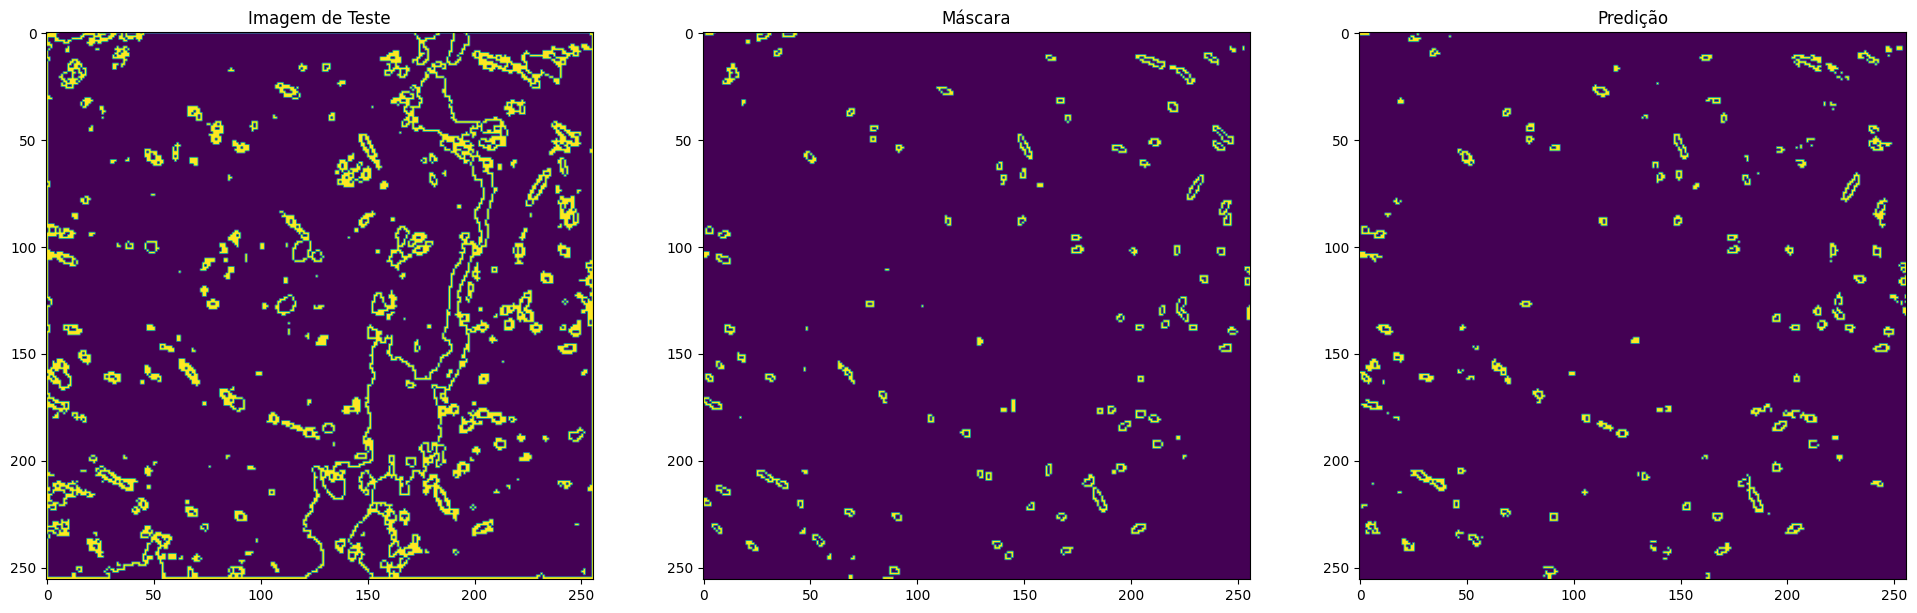

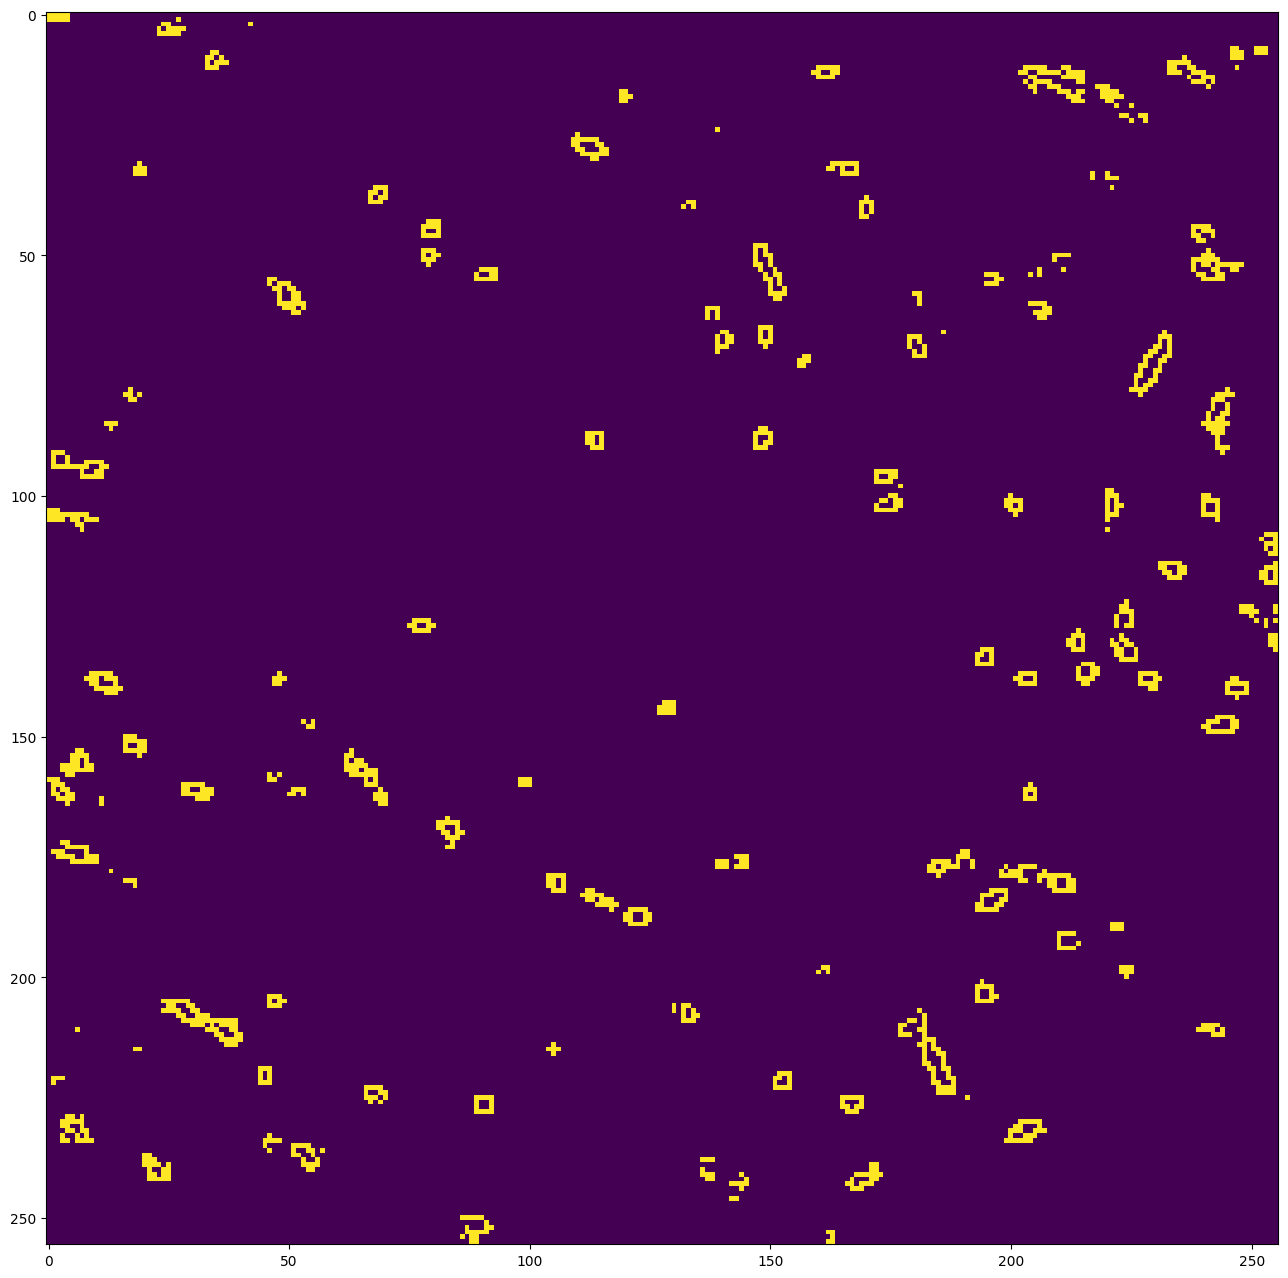

amostra 22_08 em processamento


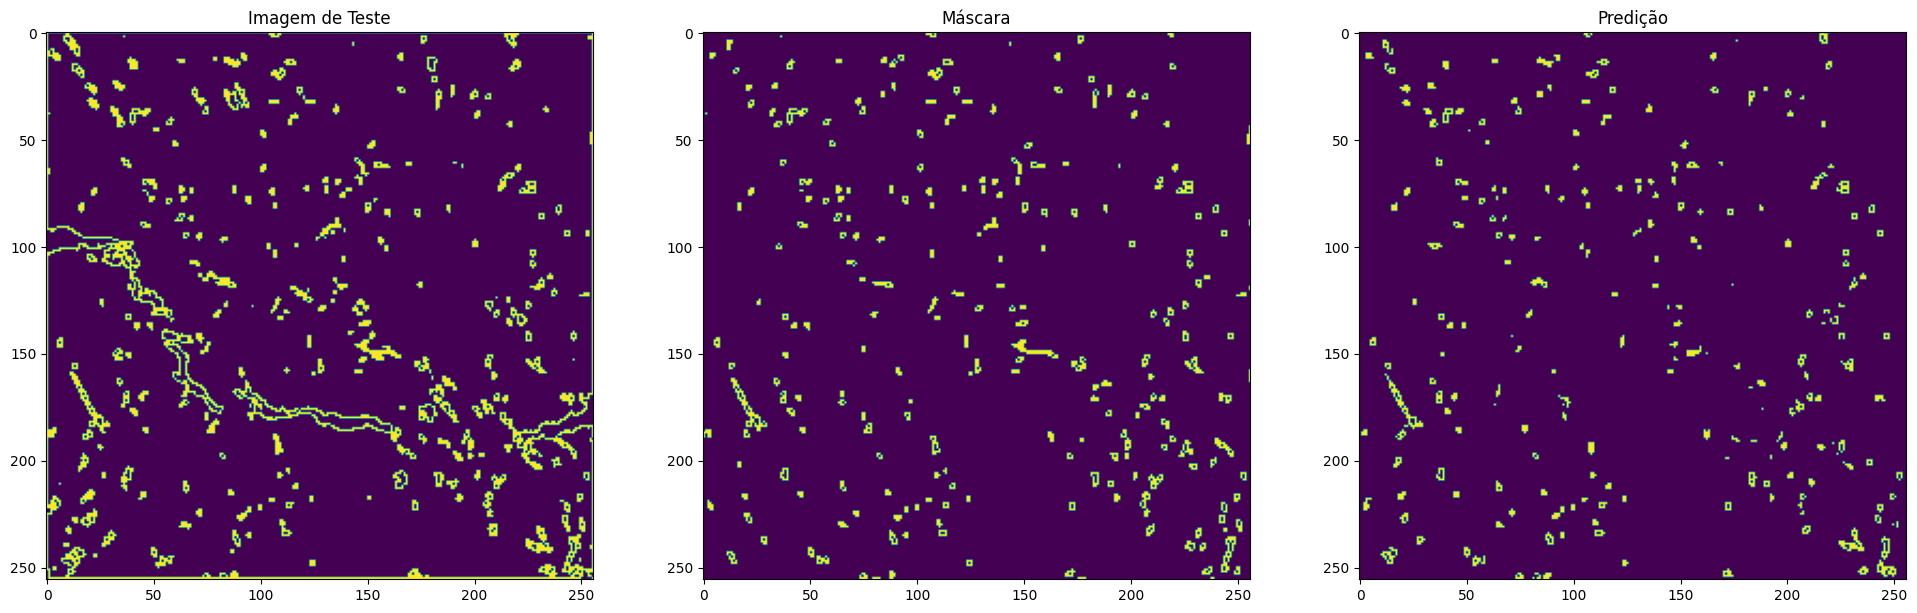

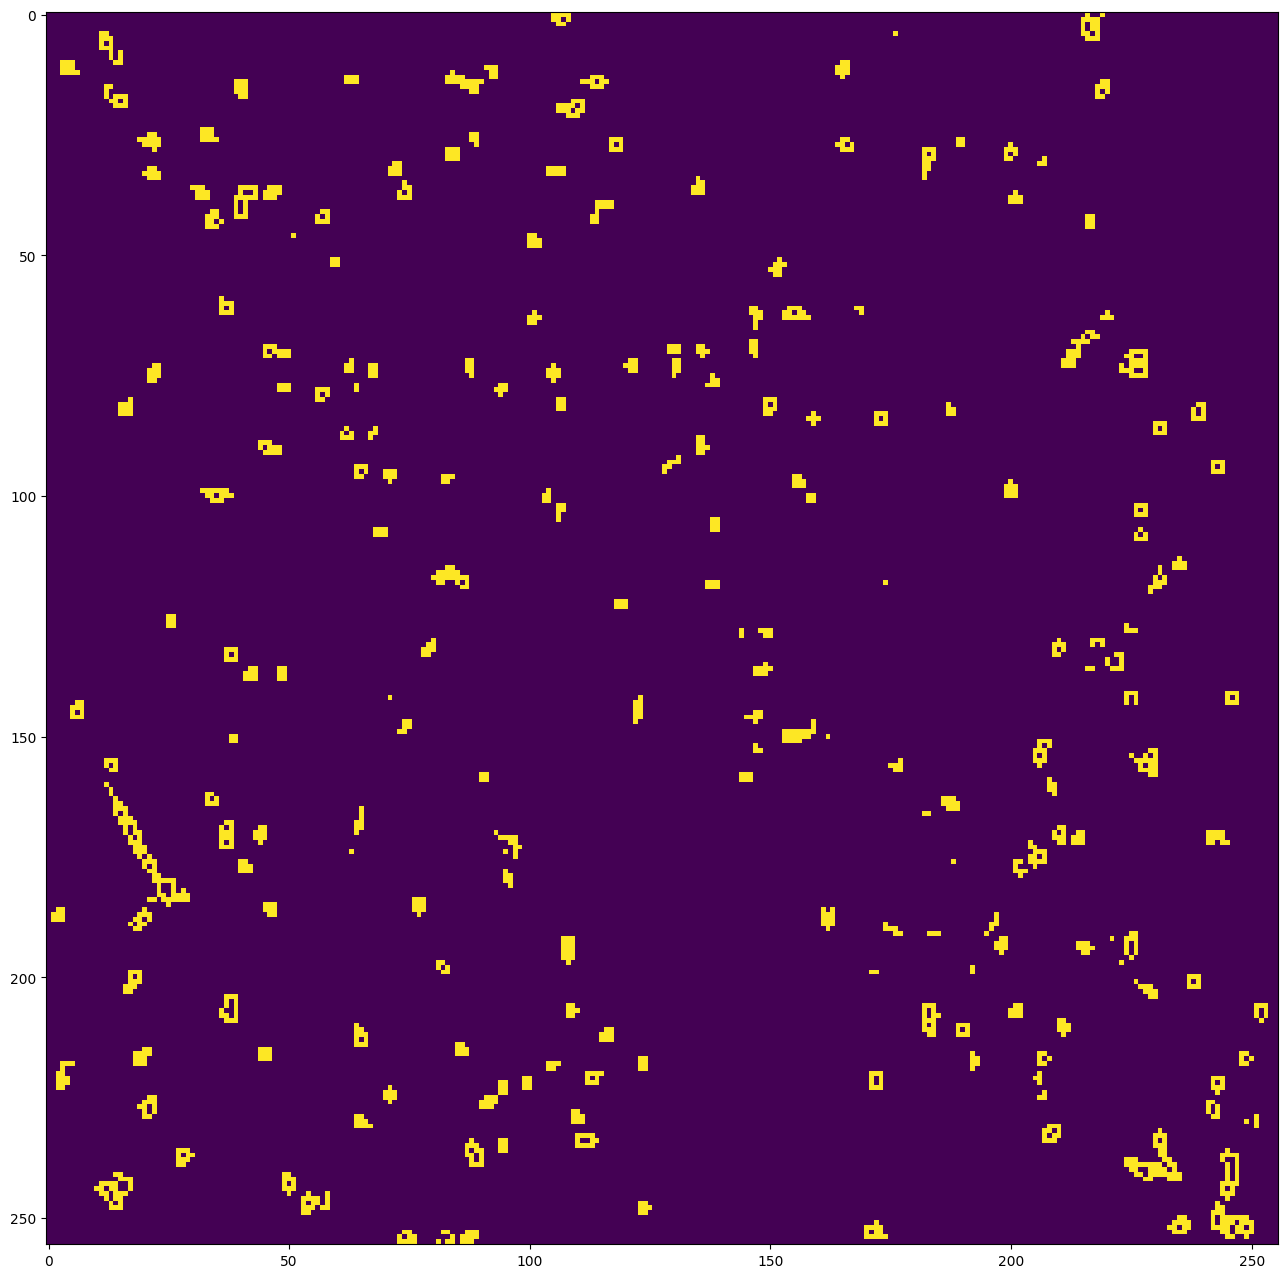

amostra 23_08 em processamento


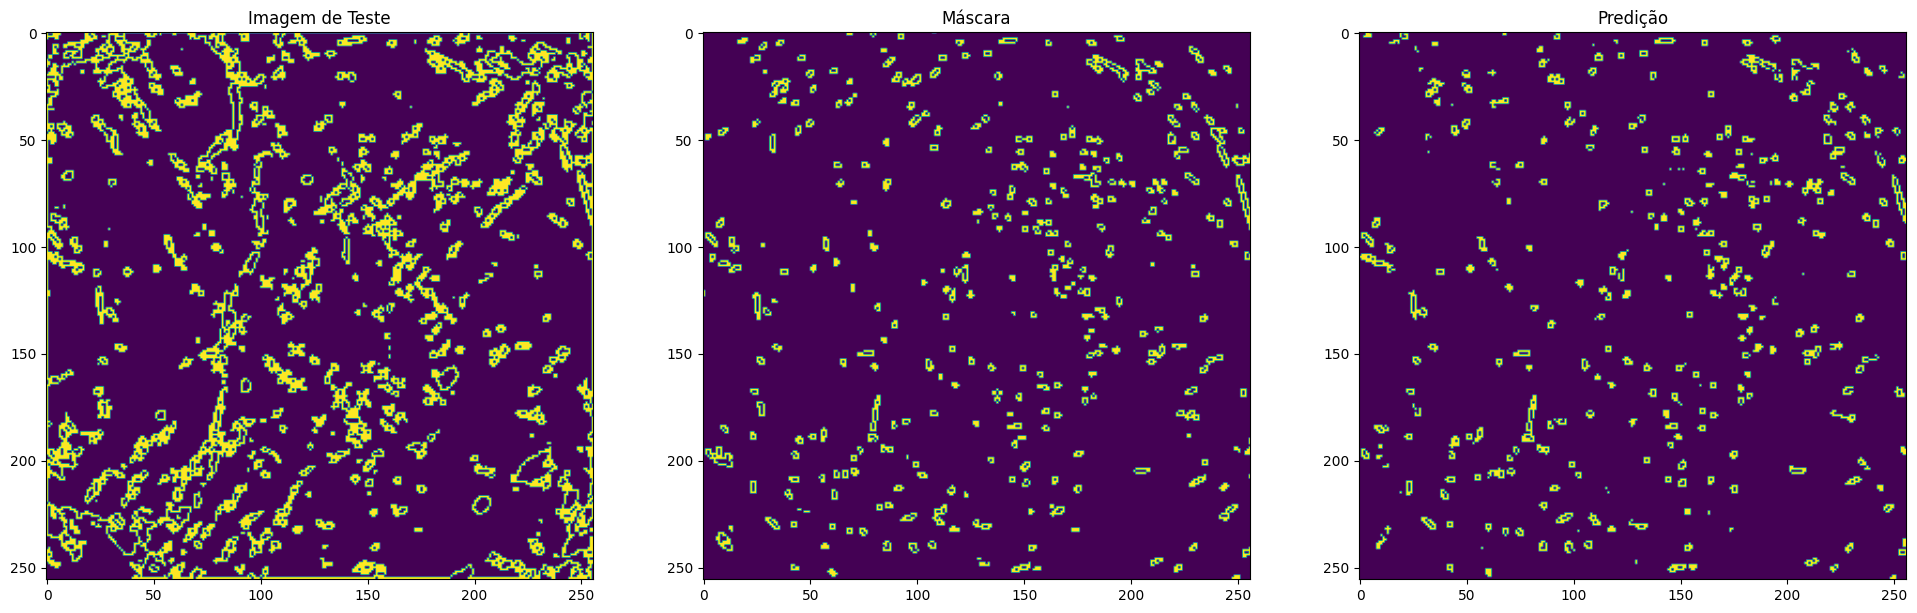

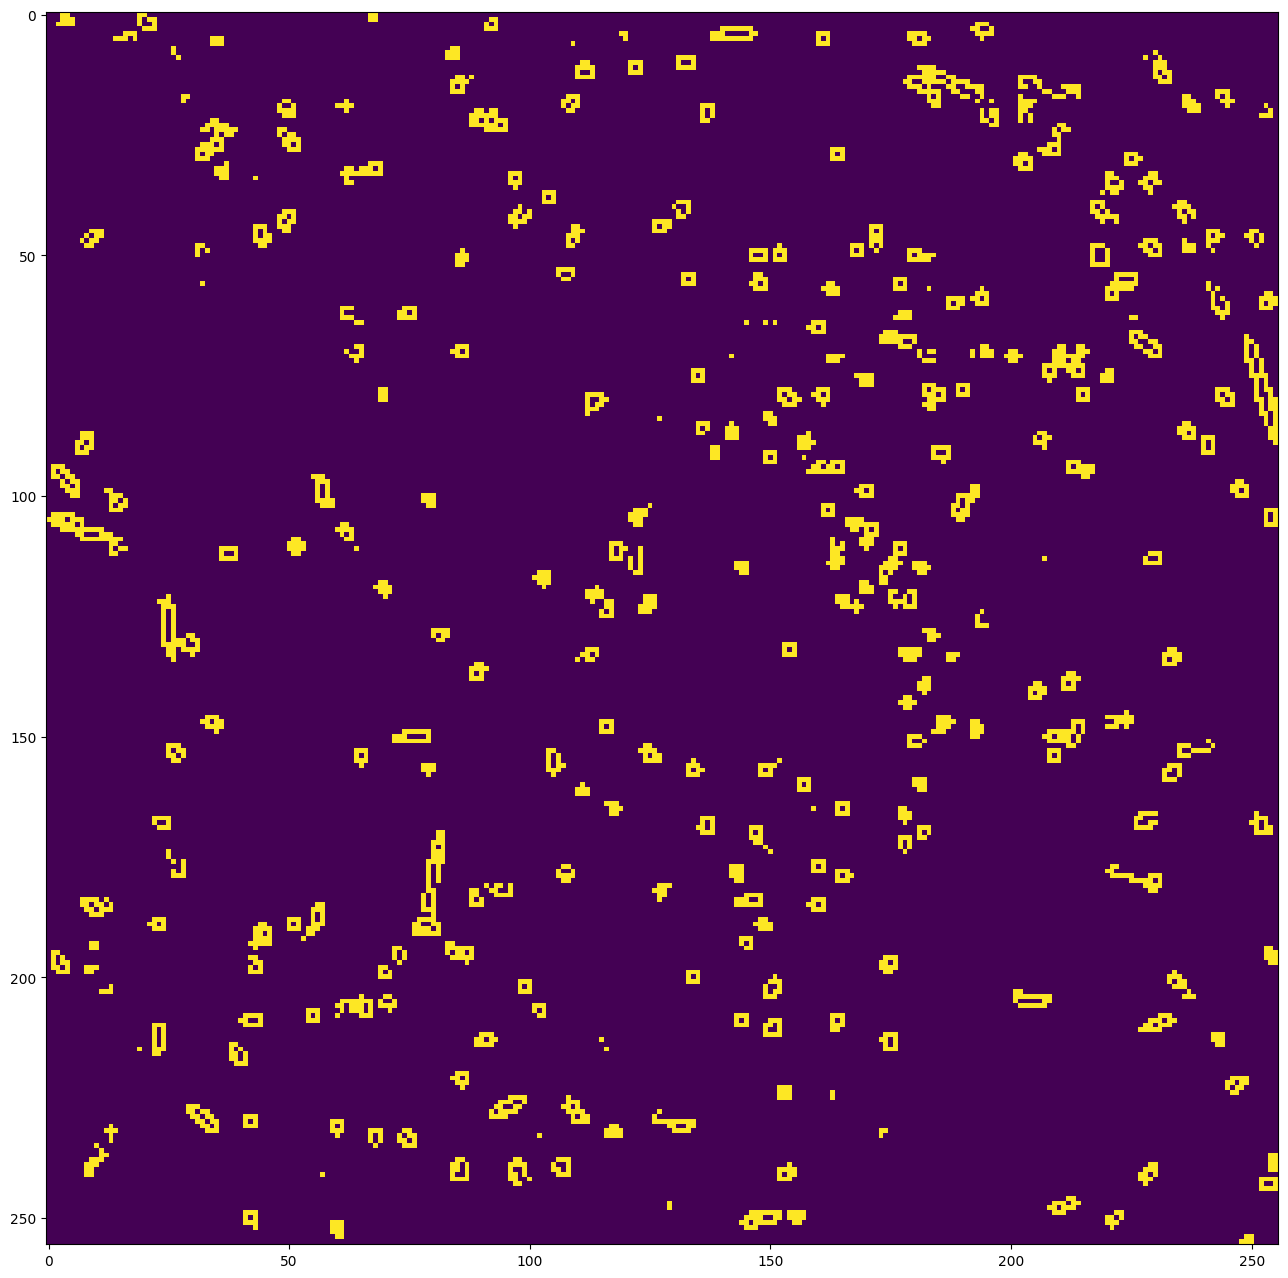

amostra 28_08 em processamento


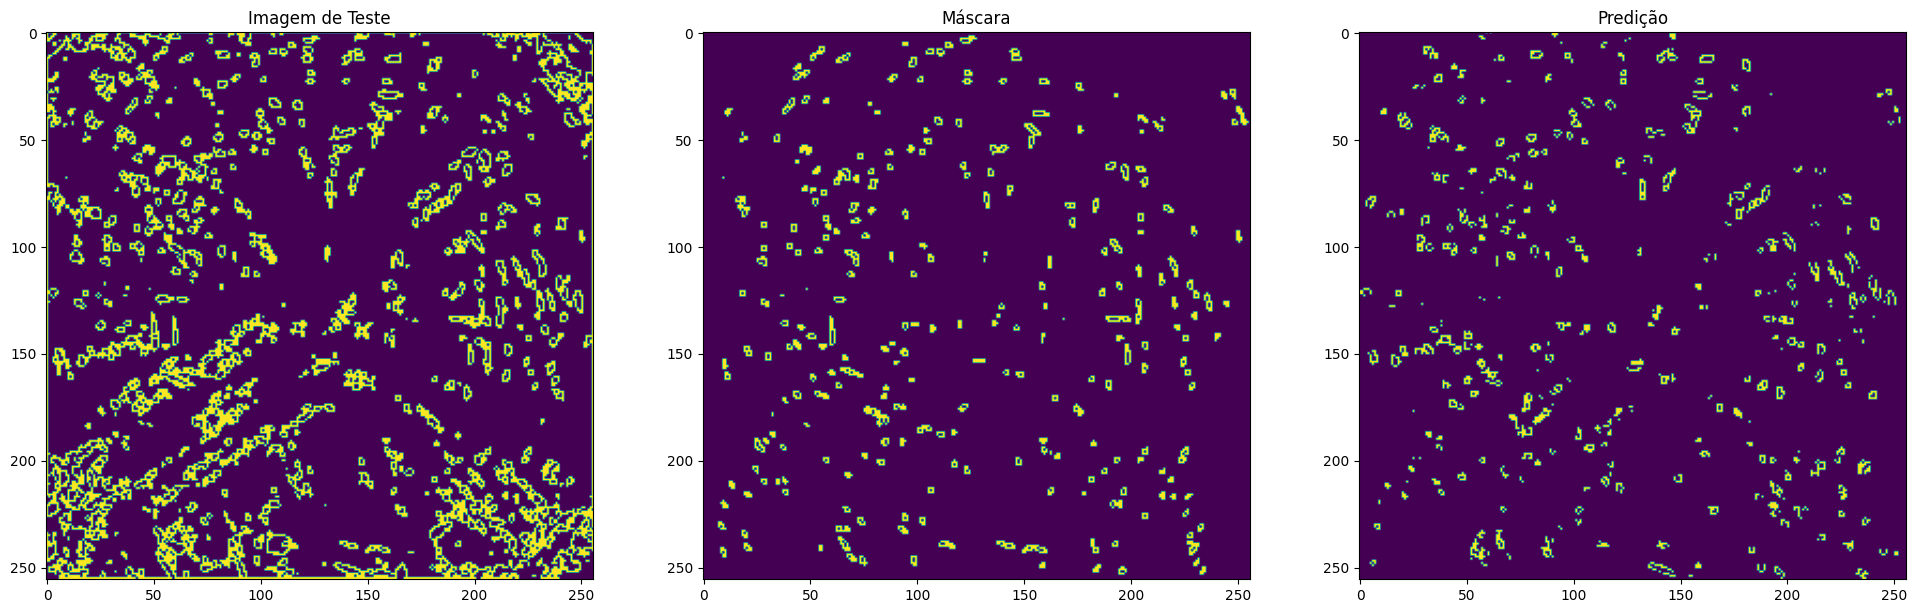

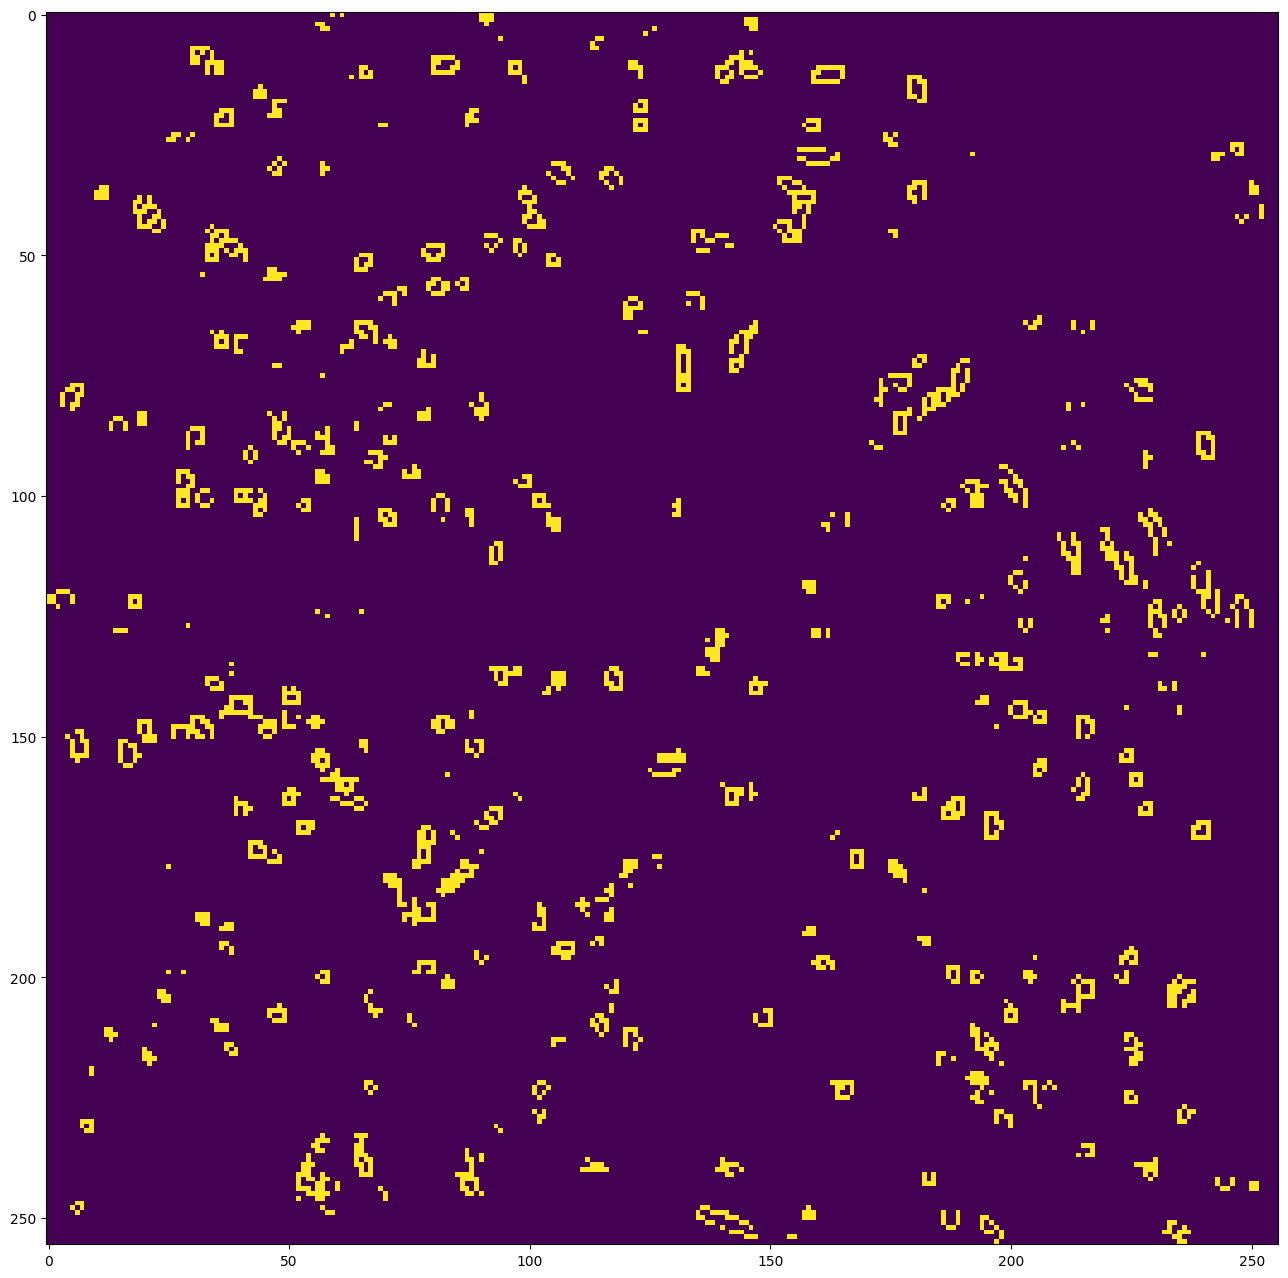

amostra 29_08 em processamento


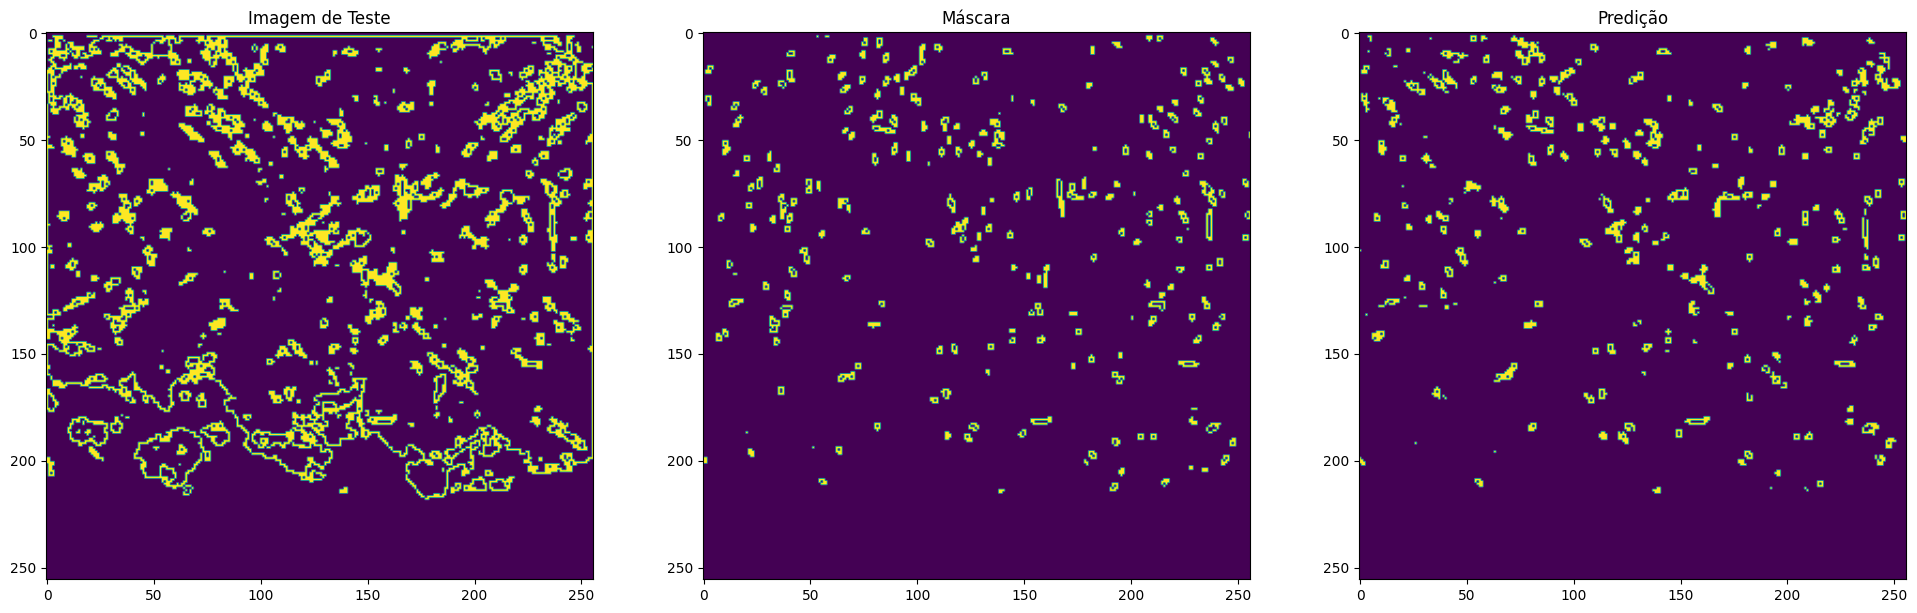

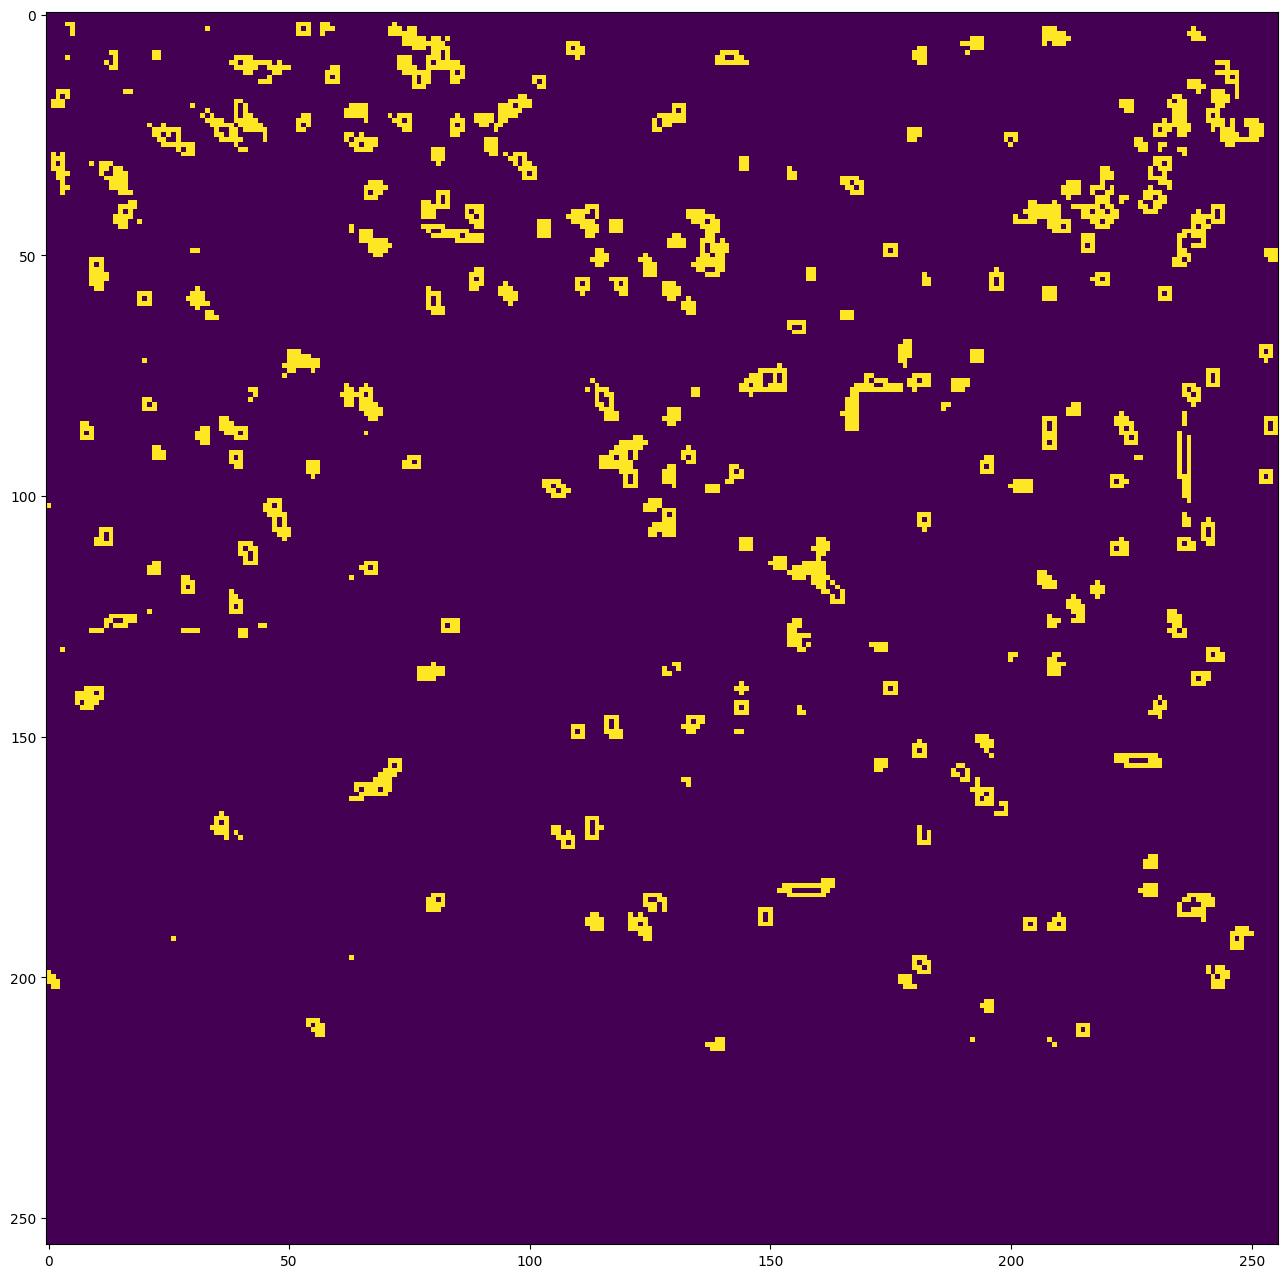

Todas amostras processadas


In [4]:
slice = 100
for file in files:
    amostra = file[:5]
    print(f'amostra {amostra} em processamento')
    image, mask = readAmostra(amostra)
    prediction = readPredicao(file)
    save_plotname = directory_path + 'comparacao/'+ amostra
    printSlicesResult(save_plotname,slice,image, mask, prediction)
    save_plotname ='result2D/'+ amostra
    printSlicePrediction(save_plotname,slice,prediction)
print(f'Todas amostras processadas')